In [1]:
import os
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

In [2]:
decoder_dirs = {
    "Simple Tanh": "STanh_TargetAlpha",
    "Simple Sigmoid": "SSigmoid_TargetAlpha",
    "MR Tanh": "MRTanh_TargetAlpha",
    "MR Sigmoid": "SSigmoid_TargetAlpha"
}

# Load CSVs for all decoders
decoder_data = {}
for name, path in decoder_dirs.items():
    training_csv = os.path.join(path, "training_summary.csv")
    eval_csv = os.path.join(path, "decoder_eval_summary.csv")
    
    if os.path.exists(training_csv) and os.path.exists(eval_csv):
        train_df = pd.read_csv(training_csv)
        eval_df = pd.read_csv(eval_csv)
        decoder_data[name] = {"train": train_df, "eval": eval_df}
    else:
        print(f"Warning: CSVs not found for {name}")

In [3]:
results = {}

for name, data in decoder_data.items():
    df = data["eval"].copy()
    df["task_awareness_score"] = df["recon_acc"] / (df["recon_CE"])

    best_score_idx = df["task_awareness_score"].idxmax()
    best_acc_idx = df["recon_acc"].idxmax()
    best_ce_idx = df["recon_CE"].idxmin()
    best_compression_idx = df["compression_pct"].idxmax()

    best_score_row = df.loc[best_score_idx]
    best_acc_row = df.loc[best_acc_idx]
    best_ce_row = df.loc[best_ce_idx]
    best_compression_row = df.loc[best_compression_idx]

    results[name] = {
        # Task-aware
        "best_score_alpha": best_score_row["alpha"],
        "best_score_value": best_score_row["task_awareness_score"],
        "best_score_acc": best_score_row["recon_acc"],
        "best_score_ce": best_score_row["recon_CE"],
        "best_score_size": best_score_row.get("recon_avg_KB", np.nan),
        "best_score_compression": best_score_row.get("compression_pct", np.nan),
        "best_score_size_acc": best_score_row.get("size_matched_lossy_acc", np.nan),
        "best_score_size_ce": best_score_row.get("size_matched_lossy_CE", np.nan),

        # Accuracy
        "best_acc_alpha": best_acc_row["alpha"],
        "best_acc_value": best_acc_row["recon_acc"],
        "best_acc_ce": best_acc_row["recon_CE"],
        "best_acc_size": best_acc_row.get("recon_avg_KB", np.nan),
        "best_acc_compression": best_acc_row.get("compression_pct", np.nan),
        "best_acc_size_acc": best_acc_row.get("size_matched_lossy_acc", np.nan),
        "best_acc_size_ce": best_acc_row.get("size_matched_lossy_CE", np.nan),

        # CE
        "best_ce_alpha": best_ce_row["alpha"],
        "best_ce_value": best_ce_row["recon_CE"],
        "best_ce_acc": best_ce_row["recon_acc"],
        "best_ce_size": best_ce_row.get("recon_avg_KB", np.nan),
        "best_ce_compression": best_ce_row.get("compression_pct", np.nan),
        "best_ce_size_acc": best_ce_row.get("size_matched_lossy_acc", np.nan),
        "best_ce_size_ce": best_ce_row.get("size_matched_lossy_CE", np.nan),

        # Compression
        "best_compression_alpha": best_compression_row["alpha"],
        "best_compression_value": best_compression_row["compression_pct"],
        "best_compression_acc": best_compression_row["recon_acc"],
        "best_compression_ce": best_compression_row["recon_CE"],
        "best_compression_size": best_compression_row.get("recon_avg_KB", np.nan),
        "best_compression_size_acc": best_compression_row.get("size_matched_lossy_acc", np.nan),
        "best_compression_size_ce": best_compression_row.get("size_matched_lossy_CE", np.nan),
    }

print("=== Task-Awareness and Performance Summary ===\n")
for name, r in results.items():
    print(f"{name}:")
    print(f"  Best Task-Aware α: {r['best_score_alpha']:.3f}")
    print(f"    Score: {r['best_score_value']:.6f}")
    print(f"    Accuracy: {r['best_score_acc']:.4f}")
    print(f"    CE: {r['best_score_ce']:.4f}")
    print(f"    Recon Size: {r['best_score_size']:.2f} KB")
    print(f"    Compression: {r['best_score_compression']:.2f}%")
    print(f"    Size-Matched Accuracy: {r['best_score_size_acc']:.4f}")
    print(f"    Size-Matched CE: {r['best_score_size_ce']:.4f}")
    print()
    print(f"  Best Accuracy α: {r['best_acc_alpha']:.3f}")
    print(f"    Accuracy: {r['best_acc_value']:.4f}")
    print(f"    CE: {r['best_acc_ce']:.4f}")
    print(f"    Recon Size: {r['best_acc_size']:.2f} KB")
    print(f"    Compression: {r['best_acc_compression']:.2f}%")
    print(f"    Size-Matched Accuracy: {r['best_acc_size_acc']:.4f}")
    print(f"    Size-Matched CE: {r['best_acc_size_ce']:.4f}")
    print()
    print(f"  Best CE α: {r['best_ce_alpha']:.3f}")
    print(f"    CE: {r['best_ce_value']:.4f}")
    print(f"    Accuracy: {r['best_ce_acc']:.4f}")
    print(f"    Recon Size: {r['best_ce_size']:.2f} KB")
    print(f"    Compression: {r['best_ce_compression']:.2f}%")
    print(f"    Size-Matched Accuracy: {r['best_ce_size_acc']:.4f}")
    print(f"    Size-Matched CE: {r['best_ce_size_ce']:.4f}")
    print()
    print(f"  Best Compression α: {r['best_compression_alpha']:.3f}")
    print(f"    Compression: {r['best_compression_value']:.2f}%")
    print(f"    Accuracy: {r['best_compression_acc']:.4f}")
    print(f"    CE: {r['best_compression_ce']:.4f}")
    print(f"    Recon Size: {r['best_compression_size']:.2f} KB")
    print(f"    Size-Matched Accuracy: {r['best_compression_size_acc']:.4f}")
    print(f"    Size-Matched CE: {r['best_compression_size_ce']:.4f}")
    print("-" * 60)


=== Task-Awareness and Performance Summary ===

Simple Tanh:
  Best Task-Aware α: 0.450
    Score: 0.528023
    Accuracy: 0.6946
    CE: 1.3155
    Recon Size: 1.26 KB
    Compression: 12.97%
    Size-Matched Accuracy: 0.4569
    Size-Matched CE: 2.4332

  Best Accuracy α: 0.450
    Accuracy: 0.6946
    CE: 1.3155
    Recon Size: 1.26 KB
    Compression: 12.97%
    Size-Matched Accuracy: 0.4569
    Size-Matched CE: 2.4332

  Best CE α: 0.010
    CE: 1.2984
    Accuracy: 0.6796
    Recon Size: 1.43 KB
    Compression: 1.48%
    Size-Matched Accuracy: 0.4592
    Size-Matched CE: 2.4140

  Best Compression α: 0.450
    Compression: 12.97%
    Accuracy: 0.6946
    CE: 1.3155
    Recon Size: 1.26 KB
    Size-Matched Accuracy: 0.4569
    Size-Matched CE: 2.4332
------------------------------------------------------------
Simple Sigmoid:
  Best Task-Aware α: 0.970
    Score: 0.655753
    Accuracy: 0.7759
    CE: 1.1832
    Recon Size: 1.30 KB
    Compression: 10.63%
    Size-Matched Accuracy:

In [4]:
results = []

for name, data in decoder_data.items():
    df = data["eval"].copy()
    df["task_awareness_score"] = df["recon_acc"] / (df["recon_CE"] + 1e-6)

    best_score_idx = df["task_awareness_score"].idxmax()
    best_acc_idx = df["recon_acc"].idxmax()
    best_ce_idx = df["recon_CE"].idxmin()
    best_compression_idx = df["compression_pct"].idxmax()

    bests = {
        "Task-Aware": df.loc[best_score_idx],
        "Accuracy": df.loc[best_acc_idx],
        "CE": df.loc[best_ce_idx],
        "Compression": df.loc[best_compression_idx],
    }

    for category, row in bests.items():
        # Decide which metrics to use based on compression
        if row.get("compression_pct", 0) >= 0:
            acc = row.get("size_matched_lossy_acc", row.get("baseline_acc", np.nan))
            ce = row.get("size_matched_lossy_CE", row.get("baseline_CE", np.nan))
        else:
            acc = row.get("baseline_acc", np.nan)
            ce = row.get("baseline_CE", np.nan)

        results.append({
            "Decoder": name,
            "Category": category,
            "Alpha": row["alpha"],

            # task-awareness
            "Task_Aware_Score": row["recon_acc"] / (row["recon_CE"] + 1e-6),

            # baseline metrics
            "Baseline_Accuracy": row.get("baseline_acc", np.nan),
            "Baseline_CE": row.get("baseline_CE", np.nan),

            # reconstruction metrics
            "Recon_Accuracy": row.get("recon_acc", np.nan),
            "Recon_CE": row.get("recon_CE", np.nan),
            "Recon_Size_KB": row.get("recon_avg_KB", np.nan),
            "Compression_%": row.get("compression_pct", np.nan),

            # size-matched or fallback
            "Size_Matched_Accuracy": acc,
            "Size_Matched_CE": ce,

            # raw training metrics
            "Raw_CE": data["train"]["raw_CE"].mean() if "raw_CE" in data["train"].columns else np.nan,
            "Raw_MSE": data["train"]["raw_MSE"].mean() if "raw_MSE" in data["train"].columns else np.nan,
            "Norm_CE": data["train"]["norm_CE"].mean() if "norm_CE" in data["train"].columns else np.nan,
            "Norm_MSE": data["train"]["norm_MSE"].mean() if "norm_MSE" in data["train"].columns else np.nan,
            "Total_Loss": data["train"]["L_Total"].mean() if "L_Total" in data["train"].columns else np.nan
        })

# Make DataFrame
summary_df = pd.DataFrame(results)

# Display
print("=== Task-Awareness and Performance Summary ===\n")
display(summary_df)

# Save to CSV
summary_csv_path = "decoder_summary_results_full.csv"
summary_df.to_csv(summary_csv_path, index=False)
print(f"\nResults saved to: {summary_csv_path}")


=== Task-Awareness and Performance Summary ===



,Decoder,Category,Alpha,Task_Aware_Score,Baseline_Accuracy,Baseline_CE,Recon_Accuracy,Recon_CE,Recon_Size_KB,Compression_%,Size_Matched_Accuracy,Size_Matched_CE,Raw_CE,Raw_MSE,Norm_CE,Norm_MSE,Total_Loss
0,Simple Tanh,Task-Aware,0.45,0.528023,0.7771,0.824283,0.6946,1.315472,1.262301,12.972436,0.4569,2.433168,0.002463,0.987814,0.039126,0.986533,0.322522
1,Simple Tanh,Accuracy,0.45,0.528023,0.7771,0.824283,0.6946,1.315472,1.262301,12.972436,0.4569,2.433168,0.002463,0.987814,0.039126,0.986533,0.322522
2,Simple Tanh,CE,0.01,0.523410,0.7771,0.824283,0.6796,1.298408,1.429036,1.477150,0.4592,2.413984,0.002463,0.987814,0.039126,0.986533,0.322522
3,Simple Tanh,Compression,0.45,0.528023,0.7771,0.824283,0.6946,1.315472,1.262301,12.972436,0.4569,2.433168,0.002463,0.987814,0.039126,0.986533,0.322522
4,Simple Sigmoid,Task-Aware,0.97,0.655753,0.7771,0.824283,0.7759,1.183220,1.296270,10.630509,0.4591,2.427868,0.003761,0.944018,0.056991,0.975923,0.542462
5,Simple Sigmoid,Accuracy,0.35,0.617092,0.7771,0.824283,0.7835,1.269663,1.220735,15.838173,0.4558,2.440055,0.003761,0.944018,0.056991,0.975923,0.542462
6,Simple Sigmoid,CE,0.97,0.655753,0.7771,0.824283,0.7759,1.183220,1.296270,10.630509,0.4591,2.427868,0.003761,0.944018,0.056991,0.975923,0.542462
7,Simple Sigmoid,Compression,0.35,0.617092,0.7771,0.824283,0.7835,1.269663,1.220735,15.838173,0.4558,2.440055,0.003761,0.944018,0.056991,0.975923,0.542462
8,MR Tanh,Task-Aware,0.18,0.567181,0.7771,0.824283,0.7515,1.324972,1.532911,-5.684399,0.7771,0.824283,0.055118,0.955474,0.180895,0.936842,0.395847
9,MR Tanh,Accuracy,0.18,0.567181,0.7771,0.824283,0.7515,1.324972,1.532911,-5.684399,0.7771,0.824283,0.055118,0.955474,0.180895,0.936842,0.395847



Results saved to: decoder_summary_results_full.csv


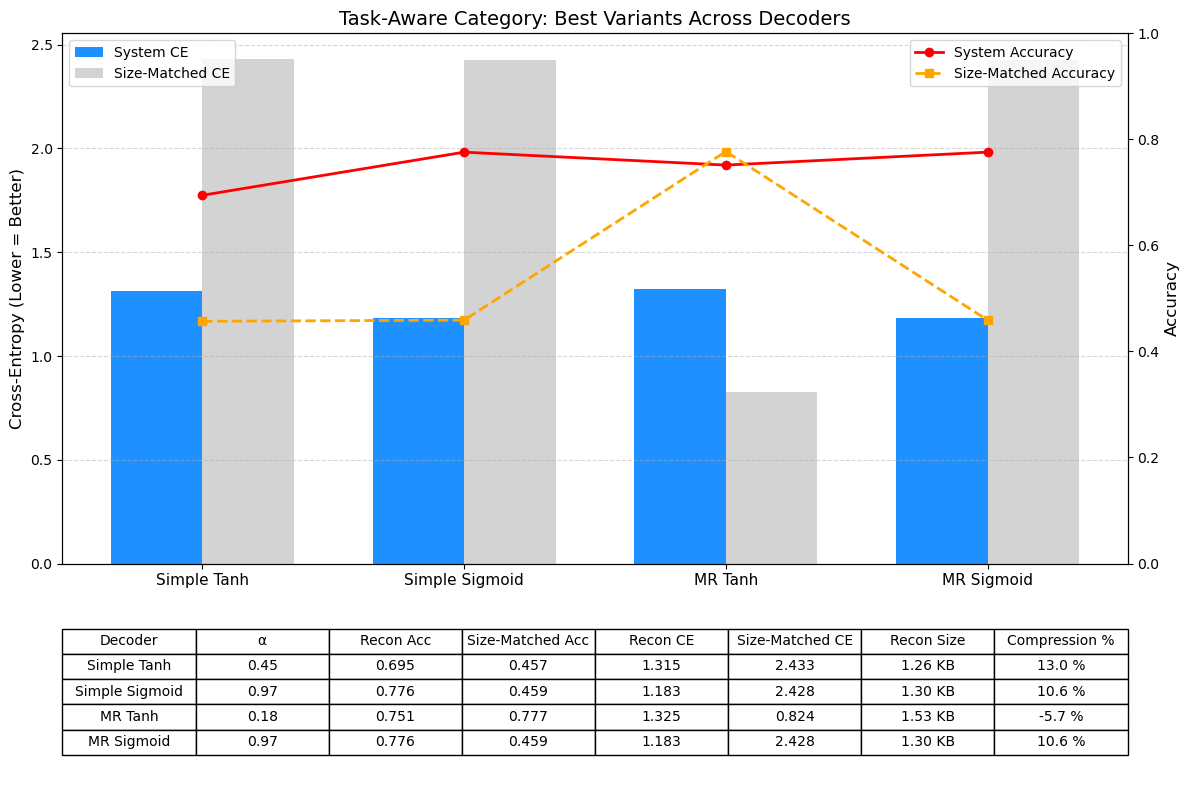

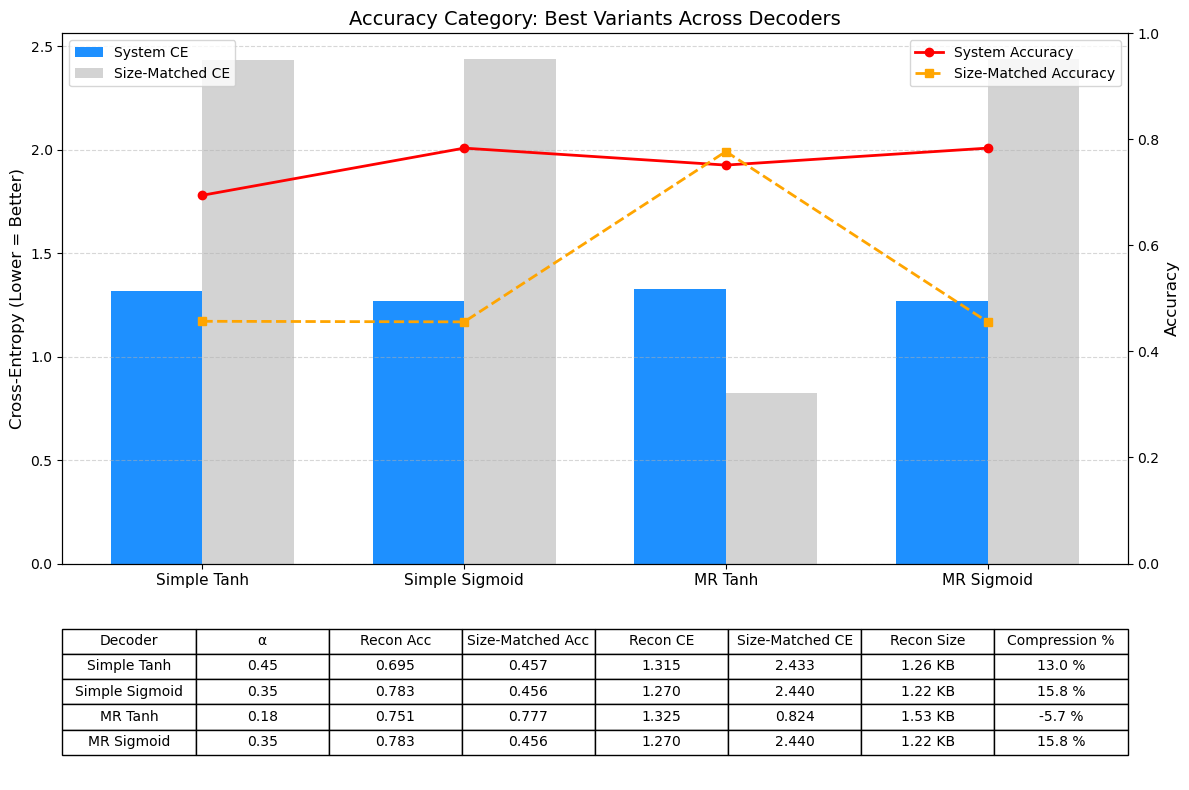

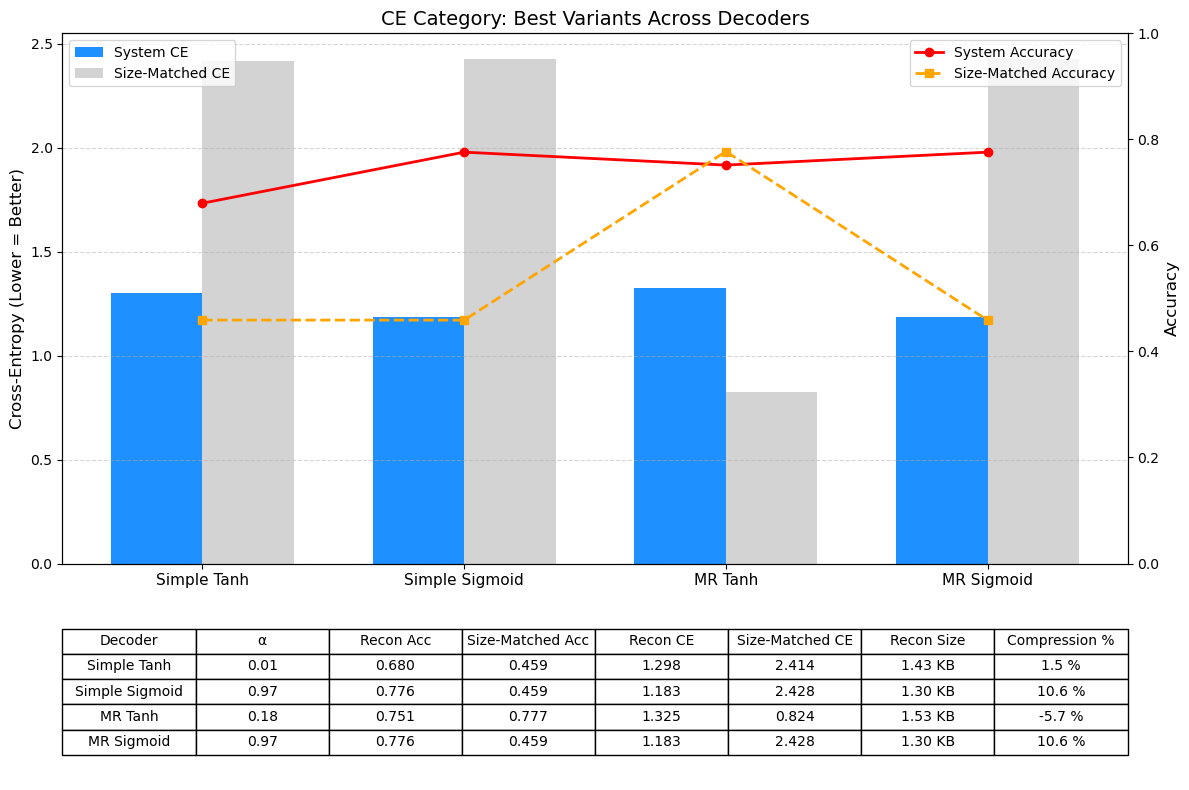

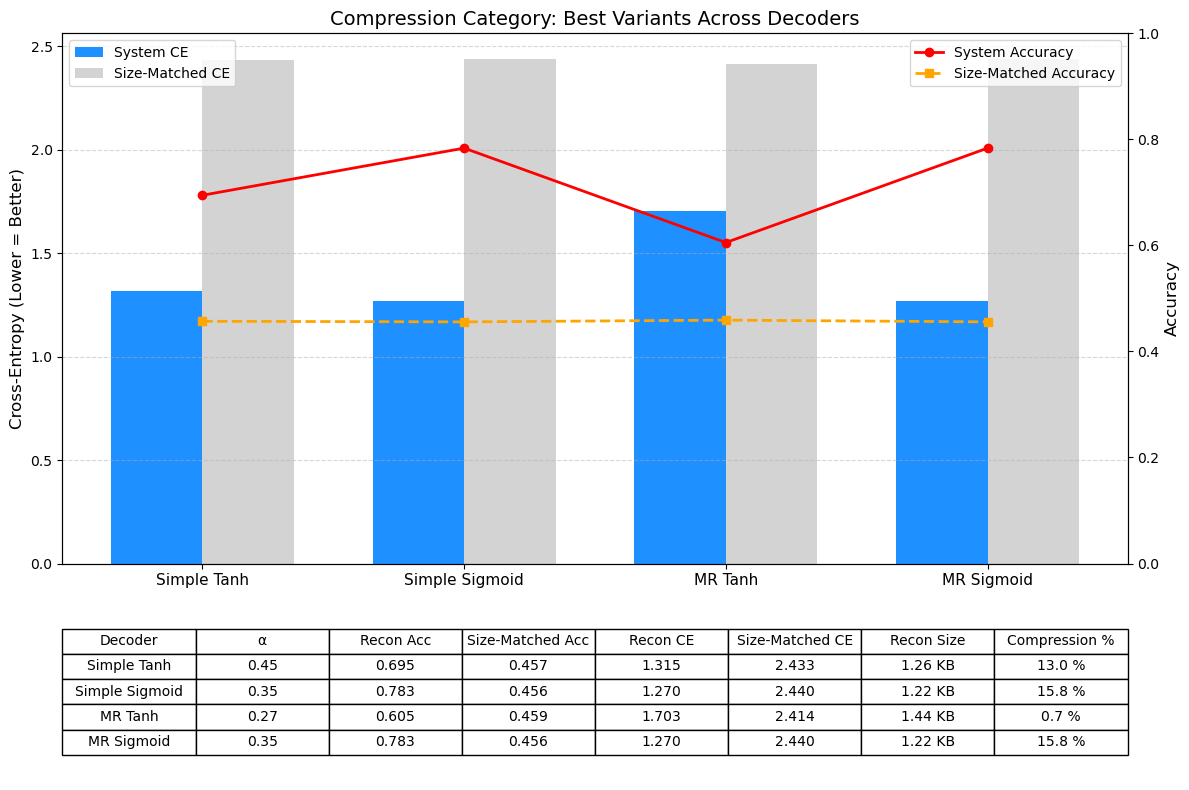

In [5]:
# Load CSV
df = pd.read_csv("decoder_summary_results_full.csv")

categories = ["Task-Aware", "Accuracy", "CE", "Compression"]
decoders = df["Decoder"].unique()

for cat in categories:
    # Filter rows for this category
    df_cat = df[df["Category"] == cat].reset_index(drop=True)
    
    system_CE = df_cat["Recon_CE"].values
    size_matched_CE = df_cat["Size_Matched_CE"].values
    system_acc = df_cat["Recon_Accuracy"].values
    size_matched_acc = df_cat["Size_Matched_Accuracy"].values
    alphas = df_cat["Alpha"].values
    recon_sizes = df_cat["Recon_Size_KB"].values
    compression_pct = df_cat["Compression_%"].values

    x = np.arange(len(decoders))
    width = 0.35

    # Create figure
    fig, gs = plt.subplots(figsize=(12,8), nrows=2, ncols=1, gridspec_kw={'height_ratios':[3,1]})
    ax1 = fig.axes[0]
    ax_table = fig.axes[1]

    # Plot CE bars (System vs Size-Matched)
    ax1.bar(x - width/2, system_CE, width, color='dodgerblue', label='System CE')
    ax1.bar(x + width/2, size_matched_CE, width, color='lightgray', label='Size-Matched CE')
    ax1.set_xticks(x)
    ax1.set_xticklabels(decoders, fontsize=11)
    ax1.set_ylabel('Cross-Entropy (Lower = Better)', fontsize=12)
    ax1.set_title(f"{cat} Category: Best Variants Across Decoders", fontsize=14)
    ax1.grid(axis='y', linestyle='--', alpha=0.5)

    # Accuracy lines (System vs Size-Matched)
    ax2 = ax1.twinx()
    ax2.plot(x, system_acc, color='red', marker='o', linestyle='-', linewidth=2, label='System Accuracy')
    ax2.plot(x, size_matched_acc, color='orange', marker='s', linestyle='--', linewidth=2, label='Size-Matched Accuracy')
    ax2.set_ylabel('Accuracy', fontsize=12)
    ax2.set_ylim(0,1)

    # Legends
    ax1.legend(loc='upper left', fontsize=10)
    ax2.legend(loc='upper right', fontsize=10)

    # Table below
    ax_table.axis('off')
    table_data = []
    for i, decoder in enumerate(decoders):
        table_data.append([
            decoder,
            f"{alphas[i]:.2f}",
            f"{system_acc[i]:.3f}",
            f"{size_matched_acc[i]:.3f}",
            f"{system_CE[i]:.3f}",
            f"{size_matched_CE[i]:.3f}",
            f"{recon_sizes[i]:.2f} KB",
            f"{compression_pct[i]:.1f} %"
        ])

    columns = ["Decoder", "α", "Recon Acc", "Size-Matched Acc", "Recon CE", "Size-Matched CE", "Recon Size", "Compression %"]
    table = ax_table.table(cellText=table_data, colLabels=columns, loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1,1.2)

    plt.tight_layout()
    plt.show()


---